In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision import models
import os, zipfile
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Mounted at /content/drive
Using device: cuda


In [ ]:
zip_path = "/content/drive/MyDrive/Road_Issues.zip"
extract_path = "/content/extracted_dataset"
split_dir = "/content/split_dataset"

if not os.path.exists(extract_path):
    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

if not all(os.path.isdir(os.path.join(split_dir, p)) for p in ["train", "val", "test"]):
    !pip install -q split-folders
    import splitfolders
    data_dir = "/content/extracted_dataset/Road Issues"
    splitfolders.ratio(data_dir, output=split_dir, ratio=(0.70, 0.15, 0.15), seed=42)

train_dir = "/content/split_dataset/train"
val_dir = "/content/split_dataset/val"
test_dir = "/content/split_dataset/test"
print("Dataset directories ready.")


Copying files: 6113 files [00:01, 4515.33 files/s]

Dataset directories ready.


In [ ]:
batch_size = 32
num_epochs = 15
num_classes = 5
features_lr = 1e-5
classifier_lr = 1e-4


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
])
transform_val_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
])


In [ ]:
train_dataset = ImageFolder(train_dir, transform=train_transform)
val_dataset = ImageFolder(val_dir, transform=transform_val_test)
test_dataset = ImageFolder(test_dir, transform=transform_val_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset.classes)
assert len(train_dataset.classes) == num_classes, f"Expected {num_classes} classes, found {len(train_dataset.classes)}"


Train images: 4276
Validation images: 914
Test images: 923
Classes: ['Broken Road Sign Issues', 'Damaged Road issues', 'Illegal Parking Issues', 'Mixed Issues', 'Pothole Issues']


In [ ]:
train_targets = np.array(train_dataset.targets)
class_counts = np.bincount(train_targets, minlength=num_classes)
print("Training images per class:")
for name, count in zip(train_dataset.classes, class_counts):
    print(f"{name}: {count}")

if np.any(class_counts == 0):
    raise ValueError("At least one class has no training images. Check dataset folders.")

class_weights_np = 1.0 / np.sqrt(class_counts.astype(np.float32))
class_weights_np = class_weights_np / class_weights_np.mean()
print("\nModerate class weights:")
for name, weight in zip(train_dataset.classes, class_weights_np):
    print(f"{name}: {weight:.4f}")
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=device)


Training images per class:
Broken Road Sign Issues: 1255
Damaged Road issues: 473
Illegal Parking Issues: 72
Mixed Issues: 133
Pothole Issues: 2343

Moderate class weights:
Broken Road Sign Issues: 0.4714
Damaged Road issues: 0.7678
Illegal Parking Issues: 1.9679
Mixed Issues: 1.4479
Pothole Issues: 0.3450


In [ ]:
weights = models.EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)

for param in model.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

for param in model.features[7].parameters():
    param.requires_grad = True
for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(device)
print(model.classifier)
print("Trainable feature block: features[7]")
print("Trainable classifier: classifier[1]")


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 134MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)
Trainable feature block: features[7]
Trainable classifier: classifier[1]


In [ ]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Total parameters: 4,013,953
Trainable parameters: 723,637


In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam([
    {"params": model.features[7].parameters(), "lr": features_lr},
    {"params": model.classifier.parameters(), "lr": classifier_lr}
])
print("Final feature block learning rate:", features_lr)
print("Classifier learning rate:", classifier_lr)


Final feature block learning rate: 1e-05
Classifier learning rate: 0.0001


In [ ]:
def evaluate_loader(loader):
    model.eval()
    all_labels, all_predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(images)
            predictions = outputs.argmax(dim=1)
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
    return np.array(all_labels), np.array(all_predictions)


In [ ]:
scaler = torch.amp.GradScaler("cuda")
best_val_macro_f1 = -1.0
best_checkpoint_path = "/content/efficientnet_b0_best.pth"

for epoch in range(num_epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / total
    train_accuracy = 100.0 * correct / total
    val_labels, val_predictions = evaluate_loader(val_loader)
    val_accuracy = accuracy_score(val_labels, val_predictions)
    val_macro_f1 = f1_score(val_labels, val_predictions, average="macro", zero_division=0)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {train_loss:.4f} Train Accuracy: {train_accuracy:.2f}% Validation Accuracy: {val_accuracy*100:.2f}% Validation Macro F1: {val_macro_f1*100:.2f}%")

    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        torch.save(model.state_dict(), best_checkpoint_path)
        print("Best EfficientNet-B0 model saved.")


Epoch [1/15] Loss: 1.2602 Train Accuracy: 70.30% Validation Accuracy: 87.31% Validation Macro F1: 54.49%
Best EfficientNet-B0 model saved.
Epoch [2/15] Loss: 0.8648 Train Accuracy: 87.56% Validation Accuracy: 90.59% Validation Macro F1: 66.38%
Best EfficientNet-B0 model saved.
Epoch [3/15] Loss: 0.7081 Train Accuracy: 89.24% Validation Accuracy: 91.47% Validation Macro F1: 70.57%
Best EfficientNet-B0 model saved.
Epoch [4/15] Loss: 0.6139 Train Accuracy: 90.25% Validation Accuracy: 91.68% Validation Macro F1: 72.11%
Best EfficientNet-B0 model saved.
Epoch [5/15] Loss: 0.5441 Train Accuracy: 90.43% Validation Accuracy: 91.47% Validation Macro F1: 72.09%
Epoch [6/15] Loss: 0.4945 Train Accuracy: 90.41% Validation Accuracy: 92.12% Validation Macro F1: 75.41%
Best EfficientNet-B0 model saved.
Epoch [7/15] Loss: 0.4583 Train Accuracy: 90.97% Validation Accuracy: 92.56% Validation Macro F1: 78.66%
Best EfficientNet-B0 model saved.
Epoch [8/15] Loss: 0.4287 Train Accuracy: 91.14% Validation A

In [ ]:
model.load_state_dict(torch.load(best_checkpoint_path, map_location=device, weights_only=True))
test_labels, test_predictions = evaluate_loader(test_loader)

accuracy = accuracy_score(test_labels, test_predictions)
precision_weighted = precision_score(test_labels, test_predictions, average="weighted", zero_division=0)
recall_weighted = recall_score(test_labels, test_predictions, average="weighted", zero_division=0)
f1_weighted = f1_score(test_labels, test_predictions, average="weighted", zero_division=0)
precision_macro = precision_score(test_labels, test_predictions, average="macro", zero_division=0)
recall_macro = recall_score(test_labels, test_predictions, average="macro", zero_division=0)
f1_macro = f1_score(test_labels, test_predictions, average="macro", zero_division=0)

print(f"Test Accuracy           : {accuracy*100:.2f}%")
print(f"Test Weighted Precision : {precision_weighted*100:.2f}%")
print(f"Test Weighted Recall    : {recall_weighted*100:.2f}%")
print(f"Test Weighted F1        : {f1_weighted*100:.2f}%")
print(f"Test Macro Precision    : {precision_macro*100:.2f}%")
print(f"Test Macro Recall       : {recall_macro*100:.2f}%")
print(f"Test Macro F1           : {f1_macro*100:.2f}%")


Test Accuracy           : 91.44%
Test Weighted Precision : 91.37%
Test Weighted Recall    : 91.44%
Test Weighted F1        : 91.33%
Test Macro Precision    : 81.65%
Test Macro Recall       : 78.82%
Test Macro F1           : 80.10%


In [ ]:
print(classification_report(test_labels, test_predictions, target_names=train_dataset.classes, digits=4, zero_division=0))


                         precision    recall  f1-score   support

Broken Road Sign Issues     0.9926    1.0000    0.9963       270
    Damaged Road issues     0.8506    0.7184    0.7789       103
 Illegal Parking Issues     0.9375    0.8824    0.9091        17
           Mixed Issues     0.3871    0.4000    0.3934        30
         Pothole Issues     0.9149    0.9404    0.9275       503

               accuracy                         0.9144       923
              macro avg     0.8165    0.7882    0.8010       923
           weighted avg     0.9137    0.9144    0.9133       923



In [ ]:
cm = confusion_matrix(test_labels, test_predictions)
print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[270   0   0   0   0]
 [  0  74   0   1  28]
 [  2   0  15   0   0]
 [  0   2   0  12  16]
 [  0  11   1  18 473]]


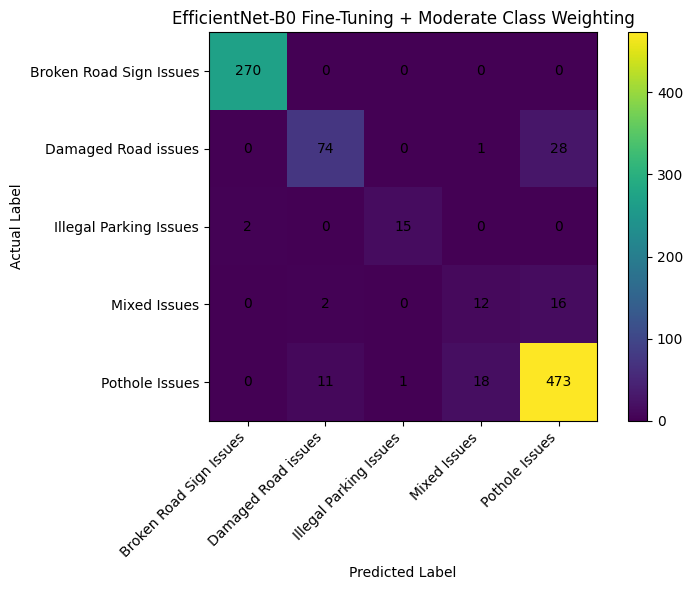

In [ ]:
plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.title("EfficientNet-B0 Fine-Tuning + Moderate Class Weighting")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(range(num_classes), train_dataset.classes, rotation=45, ha="right")
plt.yticks(range(num_classes), train_dataset.classes)
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.show()


In [ ]:
torch.save(model.state_dict(), "/content/efficientnet_b0_road_model.pth")
print("Model saved as efficientnet_b0_road_model.pth")


Model saved as efficientnet_b0_road_model.pth
